# TP Web Sémantique : l'herbier du jardinier 🌱
### URI, RDF, SPARQL, RDFS, OWL et règles SWRL avec Python

**Public visé :** élèves IODAA qui découvrent le web sémantique. Aucun prérequis en web sémantique, seulement un peu de Python.

**Fil rouge :** nous disposons d'un petit herbier (`herbier.json`, 42 plantes : famille botanique, cycle de vie, besoins en soleil et en eau). Au fil du TP, nous allons le transformer en **graphe de connaissances**, l'interroger, puis lui ajouter de l'« intelligence » grâce à une ontologie.

| Partie | Notion | Question à laquelle on répond |
|---|---|---|
| 1 | URI, triplets, RDF | Comment représenter une connaissance sous forme de graphe ? |
| 2 | SPARQL | Comment interroger ce graphe ? |
| 3 | RDFS | Comment décrire des classes et déduire de nouveaux faits ? |
| 4 | OWL | Comment exprimer des définitions, des contraintes et détecter des erreurs ? |
| 5 | SWRL | Comment écrire des règles « si ... alors ... » ? |

### Déroulement
- Les cellules **Markdown** expliquent la notion.
- Les cellules de code sont à **exécuter dans l'ordre** (`Shift+Entrée`). Le résultat attendu est décrit ou affiché.
- Les **exercices** ✏️ contiennent une requête de départ qui fonctionne mais ne répond pas encore à la question : à vous de la modifier. Les **corrigés** sont à la fin du notebook, essayez avant de les lire !

### Contribution et déclarations
- **TP existant repris :** `TP_SPARQL_Tom_Bellivier` (African Wildlife) : nous reprenons sa **progression pédagogique** (triplets, FILTER, OPTIONAL/UNION, agrégations) mais **sans copier** son contenu : autre jeu de données, autres exemples, autres exercices.
- **Notre contribution :** (1) un jeu de données réel et « en désordre » (noms avec espaces, photo manquante) qui oblige à parler d'URI ; (2) les parties **RDFS, OWL et SWRL**, absentes du TP d'origine, avec **raisonneur** (`owlrl`) ; (3) la détection d'**incohérences** ; (4) un lien avec **Protégé**.
- **Usage d'un assistant d'IA :** un assistant d'IA (Claude) a aidé à rédiger et vérifier ce notebook. Les auteurs doivent pouvoir expliquer et modifier chacune de ses parties.

## Partie 0 : Installation et chargement des données

In [1]:
# À décommenter si les bibliothèques ne sont pas installées :
# !pip install rdflib owlrl pandas matplotlib

import json
import unicodedata
from itertools import combinations

import pandas as pd
import matplotlib.pyplot as plt
from rdflib import Graph, Literal, URIRef, BNode, Namespace
from rdflib.namespace import RDF, RDFS, OWL
from owlrl import DeductiveClosure, RDFS_Semantics, OWLRL_Semantics

In [2]:
# Chargement de la base de données (fichier placé à côté du notebook)
with open("herbier.json", encoding="utf-8") as f:
    plantes = json.load(f)

print("Nombre de plantes :", len(plantes))
pd.DataFrame(plantes).head(8)

Nombre de plantes : 42


,nom,nom_scientifique,famille,cycle,besoins,photo
0,Tomate,Solanum lycopersicum,Solanaceae,annuel,"[soleil, arrosage regulier]",tomate.jpg
1,Tournesol,Helianthus annuus,Asteraceae,annuel,[soleil],tournesol.jpg
2,Haricot,Phaseolus vulgaris,Fabaceae,annuel,"[soleil, arrosage moyen]",haricot.jpg
3,Pois,Pisum sativum,Fabaceae,annuel,"[soleil, arrosage moyen]",pois.jpg
4,Lavande,Lavandula angustifolia,Lamiaceae,vivace,"[soleil, arrosage faible]",lavande.jpg
5,Menthe,Mentha sp.,Lamiaceae,vivace,"[mi ombre, arrosage frequent]",aucune_photo.png
6,Chene,Quercus robur,Fagaceae,vivace,[soleil],chene.jpg
7,Rose,Rosa gallica,Rosaceae,vivace,"[soleil, arrosage moyen]",rose.jpg


Chaque plante est un dictionnaire Python avec un nom, un nom scientifique, une famille, un cycle (`annuel`, `bisannuel`, `vivace`), une liste de besoins et une photo. C'est un format **tabulaire / arborescent** : nous allons le convertir en **graphe**.

---
## Partie 1 : URI, triplets et RDF

### Notions
- **RDF** (*Resource Description Framework*) décrit le monde avec des **triplets** `(sujet, prédicat, objet)`, c'est-à-dire des phrases très simples :

| sujet | prédicat | objet |
|---|---|---|
| Tomate | appartient à la famille | Solanaceae |
| Tomate | a pour besoin | soleil |
| Tomate | a pour nom scientifique | "Solanum lycopersicum" |

- Un ensemble de triplets forme un **graphe** : les sujets et objets sont les **nœuds**, les prédicats sont les **arêtes**.
- Chaque « chose » (la tomate, la famille, un prédicat...) est identifiée par une **URI** (*Uniform Resource Identifier*), un identifiant **unique mondialement**, qui ressemble à une adresse web, par exemple `http://example.org/herbier#Tomate`. Cela permet à deux jeux de données différents de parler de la même chose sans ambiguïté.
- L'objet peut aussi être un **littéral** : une valeur simple comme un texte ou un nombre (`"Solanum lycopersicum"`).
- Pour ne pas écrire l'URI entière à chaque fois, on utilise un **espace de noms** (*namespace*) : `herb:Tomate` est un raccourci pour `http://example.org/herbier#Tomate`.

In [3]:
# Notre espace de noms : toutes nos URI commenceront par cette adresse
HERB = Namespace("http://example.org/herbier#")

print(HERB.Tomate)          # une URI complète
print(type(HERB.Tomate))    # un objet URIRef

http://example.org/herbier#Tomate
<class 'rdflib.term.URIRef'>


### Premier triplet à la main
On crée un graphe vide et on y ajoute **un** triplet : `(Tomate, estDeFamille, Solanaceae)`.

In [4]:
mini = Graph()
mini.add((HERB.Tomate, HERB.appartientA, HERB.Solanaceae))
mini.add((HERB.Tomate, HERB.nomScientifique, Literal("Solanum lycopersicum")))

for sujet, predicat, objet in mini:
    print(sujet, "|", predicat, "|", objet)

http://example.org/herbier#Tomate | http://example.org/herbier#appartientA | http://example.org/herbier#Solanaceae
http://example.org/herbier#Tomate | http://example.org/herbier#nomScientifique | Solanum lycopersicum


### Attention aux URI : les espaces sont interdits
Dans notre fichier, certains noms posent problème : `"Pois chiche"` ou `"mi ombre"` contiennent un espace, et une URI ne peut pas contenir d'espace. Nous écrivons donc une petite fonction qui fabrique un identifiant propre (c'est ce qu'on appelle un *slug*).

In [5]:
def slug(texte):
    """Transforme un texte en identifiant utilisable dans une URI."""
    texte = unicodedata.normalize("NFD", texte)                 # sépare lettres et accents
    texte = "".join(c for c in texte if not unicodedata.combining(c))  # enlève les accents
    return texte.strip().replace(" ", "_")

print(slug("Pois chiche"))   # Pois_chiche
print(slug("mi ombre"))      # mi_ombre

Pois_chiche
mi_ombre


### Convertir tout l'herbier en graphe
Pour chaque plante, on ajoute :
- son **type** (`rdf:type`) : c'est une `Plante`,
- son **nom lisible** (`rdfs:label`),
- son **nom scientifique**, sa **famille**, son **cycle**, ses **besoins** (ce sont des *ressources* qui ont elles aussi une URI, pas de simples textes),
- sa **photo**... sauf pour la menthe : le fichier indique `aucune_photo.png`. Dans le web sémantique, **on n'écrit pas un triplet quand on ne sait pas** (hypothèse du monde ouvert, voir partie 2).

In [6]:
g = Graph()
g.bind("herb", HERB)   # pour des affichages lisibles (herb:Tomate)

for p in plantes:
    plante = HERB[slug(p["nom"])]
    famille = HERB[p["famille"]]
    cycle = HERB[p["cycle"]]

    g.add((plante, RDF.type, HERB.Plante))
    g.add((plante, RDFS.label, Literal(p["nom"])))
    g.add((plante, HERB.nomScientifique, Literal(p["nom_scientifique"])))
    g.add((plante, HERB.appartientA, famille))
    g.add((plante, HERB.aPourCycle, cycle))

    # la famille et le cycle sont eux aussi des "choses" du graphe
    g.add((famille, RDF.type, HERB.Famille))
    g.add((cycle, RDF.type, HERB.Cycle))

    for besoin in p["besoins"]:
        uri_besoin = HERB[slug(besoin)]
        g.add((plante, HERB.aPourBesoin, uri_besoin))
        g.add((uri_besoin, RDF.type, HERB.Besoin))

    if p["photo"] != "aucune_photo.png":      # donnée manquante : pas de triplet
        g.add((plante, HERB.photo, Literal(p["photo"])))

print("Le graphe contient", len(g), "triplets")

Le graphe contient 351 triplets


### Regarder le graphe
Affichons tous les triplets dont le sujet est la tomate.

In [7]:
for s, p, o in g.triples((HERB.Tomate, None, None)):    # None = "n'importe quoi"
    print(f"{s.n3(g.namespace_manager):15} {p.n3(g.namespace_manager):25} {o.n3(g.namespace_manager)}")

herb:Tomate     rdf:type                  herb:Plante
herb:Tomate     rdfs:label                "Tomate"
herb:Tomate     herb:nomScientifique      "Solanum lycopersicum"
herb:Tomate     herb:appartientA          herb:Solanaceae
herb:Tomate     herb:aPourCycle           herb:annuel
herb:Tomate     herb:aPourBesoin          herb:soleil
herb:Tomate     herb:aPourBesoin          herb:arrosage_regulier
herb:Tomate     herb:photo                "tomate.jpg"


### Le format Turtle
Pour écrire un graphe dans un fichier, on utilise des formats de sérialisation. Le plus lisible est **Turtle** (`.ttl`) : le sujet est écrit une fois, puis la liste de ses propriétés.

In [8]:
petit = Graph()
petit.bind("herb", HERB)
for t in g.triples((HERB.Tomate, None, None)):
    petit.add(t)
print(petit.serialize(format="turtle"))

@prefix herb: <http://example.org/herbier#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .

herb:Tomate a herb:Plante ;
    rdfs:label "Tomate" ;
    herb:aPourBesoin herb:arrosage_regulier,
        herb:soleil ;
    herb:aPourCycle herb:annuel ;
    herb:appartientA herb:Solanaceae ;
    herb:nomScientifique "Solanum lycopersicum" ;
    herb:photo "tomate.jpg" .




**Résultat attendu :** un bloc `herb:Tomate a herb:Plante ; herb:appartientA herb:Solanaceae ; ...`. Le mot `a` est un raccourci de Turtle pour `rdf:type`. Les points-virgules enchaînent les propriétés d'un même sujet.

On sauvegarde le graphe complet : il pourra être ouvert dans **Protégé** plus tard.

In [9]:
g.serialize(destination="herbier.ttl", format="turtle")
print("Fichier herbier.ttl écrit")

Fichier herbier.ttl écrit


---
## Partie 2 : SPARQL, le langage de requête des graphes

**SPARQL** joue pour les graphes le rôle de SQL pour les tables. Une requête décrit un **motif de graphe** (*pattern*) à retrouver. Les mots précédés de `?` sont des **variables**.

```sparql
SELECT ?nom
WHERE {
    ?plante a herb:Plante .
    ?plante rdfs:label ?nom .
}
```
Lecture : « trouve tout `?plante` qui est de type `Plante` et qui a pour label `?nom`, puis affiche `?nom` ».

- Chaque motif est un triplet qui se termine par un point `.`
- `PREFIX` déclare les raccourcis (comme en Python avec `import ... as ...`).

Pour ne pas répéter les `PREFIX` à chaque requête, on les stocke dans une variable et on écrit une petite fonction `sparql(...)` qui lance la requête et renvoie un tableau pandas.

In [10]:
PREFIXES = """
PREFIX herb: <http://example.org/herbier#>
PREFIX rdf:  <http://www.w3.org/1999/02/22-rdf-syntax-ns#>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>
PREFIX owl:  <http://www.w3.org/2002/07/owl#>
PREFIX xsd:  <http://www.w3.org/2001/XMLSchema#>
"""

def court(x):
    """Raccourcit une URI de notre herbier pour l'affichage (None = valeur absente)."""
    if x is None:
        return None
    s = str(x)
    return s.split("#")[-1] if s.startswith("http://example.org/herbier#") else s

def sparql(requete, graphe=None):
    """Lance une requête SELECT et renvoie un tableau pandas."""
    graphe = g if graphe is None else graphe
    resultat = graphe.query(PREFIXES + requete)
    lignes = [[court(v) for v in ligne] for ligne in resultat]
    return pd.DataFrame(lignes, columns=[str(v) for v in resultat.vars])

### 2.1 Première requête : lister les plantes

In [11]:
sparql("""
SELECT ?nom ?scientifique
WHERE {
    ?plante a herb:Plante .
    ?plante rdfs:label ?nom .
    ?plante herb:nomScientifique ?scientifique .
}
ORDER BY ?nom
LIMIT 10
""")

,nom,scientifique
0,Arnica,Arnica montana
1,Artichaut,Cynara cardunculus
2,Aubergine,Solanum melongena
3,Basilic,Ocimum basilicum
4,Bleuet,Centaurea cyanus
5,Camomille,Matricaria chamomilla
6,Carotte,Daucus carota
7,Cerisier,Prunus avium
8,Chene,Quercus robur
9,Chou,Brassica oleracea


**Résultat attendu :** un tableau de 10 lignes (Artichaut, Arnica, Aubergine...). `ORDER BY` trie, `LIMIT` limite le nombre de lignes.

Observez que `?plante` apparaît dans deux motifs : c'est ce qui **relie** les triplets entre eux (une jointure en SQL).

### 2.2 FILTER : restreindre les résultats
`FILTER` garde seulement les résultats qui vérifient une condition. On suit ici une **chaîne** dans le graphe : plante → famille.

In [12]:
# Les plantes de la famille des Lamiaceae (les "labiées" : menthe, lavande...)
sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    ?plante herb:appartientA herb:Lamiaceae .
}
ORDER BY ?nom
""")

,nom
0,Basilic
1,Lavande
2,Melisse
3,Menthe
4,Origano
5,Romarin
6,Sauge
7,Thym


In [13]:
# FILTER sur du texte : noms qui commencent par "P" (ou contiennent un mot)
sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    FILTER (STRSTARTS(?nom, "P"))
}
""")

,nom
0,Pois
1,Pissenlit
2,Persil
3,Pois chiche
4,Pommier
5,Prunier


Fonctions de texte utiles : `STRSTARTS`, `CONTAINS`, `STRENDS`, `LCASE`, `REGEX`. Les conditions se combinent avec `&&` (et), `||` (ou), `!` (non).

### ✏️ Exercice 1 : les légumineuses annuelles
La requête ci-dessous liste toutes les plantes de la famille des Fabaceae (les légumineuses). **Modifiez-la** pour ne garder que les plantes **annuelles** (`herb:aPourCycle herb:annuel`).

*Attendu : 4 plantes (Haricot, Pois, Gesse, Pois chiche).* *Indice : ajoutez un motif triplet (pas besoin de FILTER).*

In [ ]:
sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    ?plante herb:appartientA herb:Fabaceae .
    ## TODO
}
""")

,nom
0,Haricot
1,Pois
2,Luzerne
3,Trefle
4,Gesse
5,Pois chiche


### ✏️ Exercice 2 : le soleil sans trop d'eau
Quelles plantes ont à la fois le besoin `herb:soleil` **et** le besoin `herb:arrosage_faible` ? *Attendu : 8 plantes.* *Indice : une plante peut avoir plusieurs triplets `aPourBesoin`, il suffit de deux motifs.*

In [15]:
sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    ?plante herb:aPourBesoin herb:soleil .
    # À COMPLÉTER
}
""")

,nom
0,Tomate
1,Tournesol
2,Haricot
3,Pois
4,Lavande
5,Chene
6,Rose
7,Pissenlit
8,Basilic
9,Romarin


### 2.3 OPTIONAL : gérer les données manquantes

> **Hypothèse du monde ouvert (*Open World Assumption*)** : en web sémantique, l'absence d'un triplet ne veut pas dire que c'est faux, seulement qu'on **ne le sait pas**. La menthe n'a pas de photo dans notre graphe, ce qui ne veut pas dire qu'il n'en existe pas.

Si on demande `?plante herb:photo ?photo` dans le `WHERE`, les plantes sans photo **disparaissent** du résultat. `OPTIONAL` permet de les garder, avec une valeur vide.

In [16]:
sparql("""
SELECT ?nom ?photo
WHERE {
    ?plante rdfs:label ?nom .
    OPTIONAL { ?plante herb:photo ?photo }
}
ORDER BY ?photo
LIMIT 5
""")

,nom,photo
0,Menthe,NaN
1,Arnica,arnica.jpg
2,Artichaut,artichaut.jpg
3,Aubergine,aubergine.jpg
4,Basilic,basilic.jpg


**Résultat attendu :** la ligne `Menthe` apparaît avec une valeur vide (`None` ou `NaN`) dans la colonne photo : c'est la seule plante sans photo (le tri place les valeurs vides en premier).

On peut même chercher **ce qui manque** : on utilise `OPTIONAL` puis on garde les lignes où la variable n'a pas de valeur (`!BOUND`).

In [17]:
sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    OPTIONAL { ?plante herb:photo ?photo }
    FILTER (!BOUND(?photo))
}
""")

,nom
0,Menthe


### 2.4 UNION : « ou »
`UNION` combine deux motifs alternatifs. Ici : les plantes qui aiment **soit** la mi-ombre, **soit** un arrosage fréquent.

In [18]:
sparql("""
SELECT DISTINCT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    { ?plante herb:aPourBesoin herb:mi_ombre }
    UNION
    { ?plante herb:aPourBesoin herb:arrosage_frequent }
}
ORDER BY ?nom
""")

,nom
0,Arnica
1,Basilic
2,Epinard
3,Fraisier
4,Melisse
5,Menthe
6,Ortie
7,Persil


`DISTINCT` supprime les doublons (une plante qui vérifie les deux conditions apparaîtrait sinon deux fois).

### ✏️ Exercice 3 : les plantes de mi-ombre et leur photo
Écrivez une requête qui renvoie les plantes **à mi-ombre** (`herb:mi_ombre`) avec leur photo **si elle existe** (`OPTIONAL`). *Attendu : 7 plantes, dont la menthe avec une photo vide.*

In [19]:
sparql("""
SELECT ?nom ?photo
WHERE {
    ?plante rdfs:label ?nom .
    # À COMPLÉTER : mi-ombre + OPTIONAL photo
}
""")

,nom,photo
0,Tomate,None
1,Tournesol,None
2,Haricot,None
3,Pois,None
4,Lavande,None
5,Menthe,None
6,Chene,None
7,Rose,None
8,Pissenlit,None
9,Basilic,None


### 2.5 Agrégations : compter, regrouper
- `COUNT`, `AVG`, `MIN`, `MAX`... calculent des statistiques.
- `GROUP BY` regroupe les lignes par valeur d'une variable.
- `HAVING` filtre les groupes (comme en SQL).

In [20]:
res = sparql("""
SELECT ?famille (COUNT(?plante) AS ?nombre)
WHERE {
    ?plante herb:appartientA ?famille .
}
GROUP BY ?famille
ORDER BY DESC(?nombre)
""")
res["nombre"] = res["nombre"].astype(int)
res

,famille,nombre
0,Asteraceae,11
1,Lamiaceae,8
2,Fabaceae,6
3,Rosaceae,6
4,Solanaceae,2
5,Apiaceae,2
6,Fagaceae,1
7,Urticaceae,1
8,Amaranthaceae,1
9,Papaveraceae,1


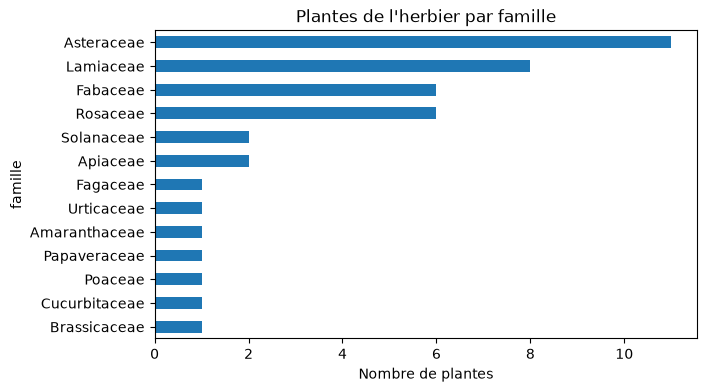

In [21]:
# Un graphique pour visualiser le résultat
res.plot.barh(x="famille", y="nombre", legend=False, figsize=(7, 4))
plt.xlabel("Nombre de plantes")
plt.title("Plantes de l'herbier par famille")
plt.gca().invert_yaxis()
plt.show()

### ✏️ Exercice 4 : les besoins les plus fréquents
Comptez combien de plantes ont chaque besoin (`?besoin`), triez du plus fréquent au moins fréquent. Puis ajoutez `HAVING (COUNT(?plante) >= 10)` pour ne garder que les besoins partagés par au moins 10 plantes. *Attendu : 3 lignes (soleil en tête).*

In [22]:
sparql("""
SELECT ?besoin
WHERE {
    ?plante herb:aPourBesoin ?besoin .
    # À COMPLÉTER : COUNT, GROUP BY, ORDER BY...
}
""")

,besoin
0,soleil
1,soleil
2,soleil
3,soleil
4,soleil
...,...
73,mi_ombre
74,mi_ombre
75,mi_ombre
76,arrosage_frequent


---
## Partie 3 : RDFS, donner un vocabulaire au graphe

Jusqu'ici nous avons seulement des **données** (des faits sur la tomate, la menthe...). **RDFS** (*RDF Schema*) permet d'écrire le **schéma** : quelles sont les classes, comment elles s'emboîtent, et ce que signifient les propriétés. Le tout est exprimé... en triplets !

| Mot-clé RDFS | Signification | Exemple |
|---|---|---|
| `rdfs:Class` | déclare une classe | `herb:Plante a rdfs:Class` |
| `rdfs:subClassOf` | sous-classe (« est une sorte de ») | `herb:Arbre rdfs:subClassOf herb:Plante` |
| `rdfs:domain` | le **sujet** de la propriété est de cette classe | `aPourBesoin` a pour domaine `Plante` |
| `rdfs:range` | l'**objet** de la propriété est de cette classe | `aPourBesoin` a pour portée `Besoin` |

Un **raisonneur** (*reasoner*) peut alors **déduire** des triplets qui n'ont jamais été écrits.

### 3.1 Écrire le schéma

In [23]:
# Classes
for classe in ["EtreVivant", "Plante", "Arbre", "PlanteAromatique", "Famille", "Cycle", "Besoin"]:
    g.add((HERB[classe], RDF.type, RDFS.Class))

# Hiérarchie : Arbre et PlanteAromatique sont des sortes de Plante, qui est un EtreVivant
g.add((HERB.Plante, RDFS.subClassOf, HERB.EtreVivant))
g.add((HERB.Arbre, RDFS.subClassOf, HERB.Plante))
g.add((HERB.PlanteAromatique, RDFS.subClassOf, HERB.Plante))

# Propriétés : domaine (sujet) et portée (objet)
for propriete, domaine, portee in [
    ("appartientA", "Plante", "Famille"),
    ("aPourCycle",  "Plante", "Cycle"),
    ("aPourBesoin", "Plante", "Besoin"),
]:
    g.add((HERB[propriete], RDF.type, RDF.Property))
    g.add((HERB[propriete], RDFS.domain, HERB[domaine]))
    g.add((HERB[propriete], RDFS.range, HERB[portee]))

### 3.2 Enrichir les données (notre ajout manuel)
`herbier.json` ne dit pas quelles plantes sont des arbres ou des aromatiques. Nous l'ajoutons nous-mêmes avec une connaissance de jardinier : c'est le rôle d'une ontologie d'**enrichir** les données brutes.

In [24]:
arbres = ["Chene", "Pommier", "Cerisier", "Prunier"]
aromatiques = ["Lavande", "Menthe", "Basilic", "Romarin", "Thym", "Sauge",
               "Persil", "Estragon", "Melisse", "Origano"]

for nom in arbres:
    g.add((HERB[nom], RDF.type, HERB.Arbre))
for nom in aromatiques:
    g.add((HERB[nom], RDF.type, HERB.PlanteAromatique))

print("Graphe enrichi :", len(g), "triplets")

Graphe enrichi : 384 triplets


### 3.3 Sans raisonneur : ce que dit seulement le graphe
Posons une question dont la réponse **n'est écrite nulle part** dans le graphe : *combien y a-t-il d'`EtreVivant` ?* Aucun triplet ne dit qu'une chose est un `EtreVivant`.

In [25]:
sparql("""
SELECT (COUNT(DISTINCT ?x) AS ?nombre)
WHERE { ?x a herb:EtreVivant }
""")

,nombre
0,0


**Résultat attendu :** 0. Personne n'est *explicitement* un `EtreVivant`.

### 3.4 Avec raisonneur RDFS
On travaille sur une **copie** du graphe (`inf`) pour garder `g` intact, puis on laisse la bibliothèque `owlrl` appliquer les règles de RDFS jusqu'à ce qu'il n'y ait plus rien à déduire (*fermeture déductive*).

In [26]:
inf = Graph()
inf += g                                   # copie de g
avant = len(inf)
DeductiveClosure(RDFS_Semantics).expand(inf)
print(f"Triplets avant : {avant}, après raisonnement : {len(inf)}")

sparql("""
SELECT (COUNT(DISTINCT ?x) AS ?nombre)
WHERE { ?x a herb:EtreVivant }
""", inf)

Triplets avant : 384, après raisonnement : 662


,nombre
0,42


**Résultat attendu :** 42, car `Tomate a Plante` + `Plante subClassOf EtreVivant` ⟹ `Tomate a EtreVivant`. Vérifions que les déductions ne vont que **vers le haut** de la hiérarchie : la tomate n'est pas devenue un `Arbre`.

In [27]:
sparql("""
SELECT ?nom
WHERE {
    ?x a herb:Plante .
    ?x rdfs:label ?nom .
    FILTER NOT EXISTS { ?x a herb:Arbre }
    FILTER (?nom IN ("Chene", "Tomate"))
}
""", inf)

,nom
0,Tomate


Seule la tomate apparaît (« plante mais pas arbre ») : le chêne, lui, est bien un `Arbre`.

### 3.5 Domain et range : déduire le type d'après l'usage
Ajoutons une plante mystérieuse dont on sait **seulement** qu'elle a besoin de soleil. Comme `aPourBesoin` a pour domaine `Plante`, le raisonneur en déduit que c'est une plante, et que `soleil` est un `Besoin`.

In [28]:
test = Graph()
test += g
test.add((HERB.Mystere, HERB.aPourBesoin, HERB.soleil))      # un seul triplet !
DeductiveClosure(RDFS_Semantics).expand(test)

print("Mystere est une Plante ?", (HERB.Mystere, RDF.type, HERB.Plante) in test)
print("Mystere est un EtreVivant ?", (HERB.Mystere, RDF.type, HERB.EtreVivant) in test)

Mystere est une Plante ? True
Mystere est un EtreVivant ? True


### ✏️ Exercice 5 : classes d'une plante
Sur le graphe `inf` (celui avec raisonnement), listez **toutes les classes** (`?classe`) auxquelles appartient le thym (`herb:Thym`). Utilisez `herb:Thym a ?classe`. *Attendu : Plante, PlanteAromatique, EtreVivant, et quelques classes techniques ajoutées par RDFS (`rdfs:Resource`...).*

In [29]:
sparql("""
SELECT ?classe
WHERE {
    # À COMPLÉTER
    ?x a ?classe .
}
LIMIT 3
""", inf)

,classe
0,Plante
1,Plante
2,Plante


---
## Partie 4 : OWL, une ontologie plus expressive

**OWL** (*Web Ontology Language*) étend RDFS avec plus de puissance : définitions précises, contraintes et détection d'erreurs. Nous en utilisons trois idées.

| Idée OWL | Rôle | Dans l'herbier |
|---|---|---|
| `owl:inverseOf` | deux propriétés « inverses » | `aPourBesoin` ↔ `estBesoinDe` |
| `owl:disjointWith`, `owl:differentFrom`, `owl:FunctionalProperty` | **contraintes** | une plante n'est pas une famille ; une plante n'a qu'un cycle |
| `owl:equivalentClass` + `owl:Restriction` | **classe définie** par une condition | « plante de soleil » = toute plante qui a le besoin soleil |

Nous construisons l'ontologie OWL dans un nouveau graphe `onto` (copie de `g`).

### 4.1 Propriété inverse

In [30]:
onto = Graph()
onto += g
onto.bind("herb", HERB)

# les classes sont maintenant des classes OWL
for classe in ["EtreVivant", "Plante", "Arbre", "PlanteAromatique", "Famille", "Cycle", "Besoin"]:
    onto.add((HERB[classe], RDF.type, OWL.Class))

# propriété inverse : si "Tomate aPourBesoin soleil" alors "soleil estBesoinDe Tomate"
onto.add((HERB.aPourBesoin, RDF.type, OWL.ObjectProperty))
onto.add((HERB.aPourBesoin, OWL.inverseOf, HERB.estBesoinDe))
print("Ontologie OWL initialisée :", len(onto), "triplets")

Ontologie OWL initialisée : 393 triplets


### 4.2 Classes définies par une restriction
On définit : **`PlanteDeSoleil` ≡ tout ce qui a pour besoin `soleil`**. En OWL, une condition sur une propriété s'écrit avec une *restriction* (un nœud anonyme, `BNode`) :
- `owl:onProperty` : la propriété concernée,
- `owl:hasValue` : la valeur exigée.

Les plantes n'ont **pas** besoin d'être déclarées `PlanteDeSoleil` : le raisonneur le fera.

In [31]:
def definir_classe(nom_classe, propriete, valeur):
    """Déclare : nom_classe ≡ (ce qui a  propriete = valeur)."""
    restriction = BNode()
    onto.add((HERB[nom_classe], RDF.type, OWL.Class))
    onto.add((HERB[nom_classe], OWL.equivalentClass, restriction))
    onto.add((restriction, RDF.type, OWL.Restriction))
    onto.add((restriction, OWL.onProperty, HERB[propriete]))
    onto.add((restriction, OWL.hasValue, HERB[valeur]))

definir_classe("PlanteDeSoleil", "aPourBesoin", "soleil")
definir_classe("PlanteVivace", "aPourCycle", "vivace")

### 4.3 Lancer le raisonneur OWL

In [32]:
ontologie_inferee = Graph()
ontologie_inferee += onto
DeductiveClosure(OWLRL_Semantics).expand(ontologie_inferee)
print(f"Triplets : {len(onto)} → {len(ontologie_inferee)} après raisonnement OWL")

print("\nPlantes vivaces de soleil (déduites, jamais écrites dans le fichier) :")
sparql("""
SELECT ?nom
WHERE {
    ?p a herb:PlanteVivace .
    ?p a herb:PlanteDeSoleil .
    ?p rdfs:label ?nom .
}
ORDER BY ?nom
""", ontologie_inferee)

Triplets : 403 → 1091 après raisonnement OWL

Plantes vivaces de soleil (déduites, jamais écrites dans le fichier) :


,nom
0,Cerisier
1,Chene
2,Estragon
3,Framboisier
4,Lavande
5,Luzerne
6,Marguerite
7,Origano
8,Pissenlit
9,Pommier


In [33]:
# Propriété inverse : quelles plantes ont besoin de "soleil" ? (on lit la propriété dans l'autre sens)
sparql("""
SELECT (COUNT(?p) AS ?nombre)
WHERE { herb:soleil herb:estBesoinDe ?p }
""", ontologie_inferee)

,nombre
0,35


### ✏️ Exercice 6 : définir « PlanteDeMiOmbre »
En vous inspirant de `definir_classe`, définissez la classe `PlanteDeMiOmbre` (besoin `mi_ombre`), relancez le raisonneur et comptez ses membres. *Attendu : 7.* *(Le code de départ ne crée pas encore la classe : il affichera 0.)*

In [34]:
# À COMPLÉTER : definir_classe(...)

essai = Graph()
essai += onto
DeductiveClosure(OWLRL_Semantics).expand(essai)

sparql("SELECT (COUNT(?p) AS ?nombre) WHERE { ?p a herb:PlanteDeMiOmbre }", essai)

,nombre
0,0


### 4.4 Contraintes et détection d'incohérences
Une ontologie sert aussi à **repérer des erreurs dans les données**. Ajoutons des contraintes :
1. Les classes `Plante`, `Famille`, `Cycle`, `Besoin` sont **disjointes** : aucune chose ne peut être à la fois une plante et une famille.
2. `aPourCycle` est une propriété **fonctionnelle** : une plante a **au plus un** cycle.
3. Les trois cycles sont **différents** (`owl:differentFrom`).

In [35]:
for a, b in combinations(["Plante", "Famille", "Cycle", "Besoin"], 2):
    onto.add((HERB[a], OWL.disjointWith, HERB[b]))

onto.add((HERB.aPourCycle, RDF.type, OWL.FunctionalProperty))

for a, b in combinations(["annuel", "bisannuel", "vivace"], 2):
    onto.add((HERB[a], OWL.differentFrom, HERB[b]))

def erreurs(graphe):
    """Lance le raisonneur sur une copie et renvoie les incohérences détectées."""
    copie = Graph()
    copie += graphe
    DeductiveClosure(OWLRL_Semantics).expand(copie)
    ERREUR = URIRef("http://www.daml.org/2002/03/agents/agent-ont#error")
    return [str(o) for o in copie.objects(None, ERREUR)]

print("Erreurs dans l'herbier actuel :", erreurs(onto))

Erreurs dans l'herbier actuel : []


**Résultat attendu :** `[]` (aucune erreur). Introduisons maintenant **deux erreurs** de saisie.

In [36]:
# Erreur 1 : la tomate est déclarée à la fois annuelle ET vivace
test1 = Graph(); test1 += onto
test1.add((HERB.Tomate, HERB.aPourCycle, HERB.vivace))
print("Erreur 1 :", erreurs(test1)[:1])

# Erreur 2 : "Lamiaceae" est déclarée à la fois Famille et Plante
test2 = Graph(); test2 += onto
test2.add((HERB.Lamiaceae, RDF.type, HERB.Plante))
print("Erreur 2 :", erreurs(test2)[:1])

Erreur 1 : ["'sameAs' and 'differentFrom' cannot be used on the same subject-object pair: (http://example.org/herbier#vivace, http://example.org/herbier#annuel)"]
Erreur 2 : ['Disjoint classes http://example.org/herbier#Plante and http://example.org/herbier#Famille have a common individual http://example.org/herbier#Lamiaceae']


**Résultat attendu :** deux messages d'erreur (le premier parle de `sameAs` et `differentFrom`). Raisonnement du premier cas : comme `aPourCycle` est fonctionnelle, la tomate n'a qu'**un** cycle, donc `annuel` et `vivace` désigneraient la même chose... or on a dit qu'ils sont différents. Contradiction !

> **Remarque :** les messages de `owlrl` sont techniques ; l'essentiel est qu'une liste non vide signale un problème. Dans Protégé, un raisonneur (HermiT) affiche « Inconsistent ontology » dans ce cas.

On sauvegarde l'ontologie pour l'ouvrir dans Protégé :

In [37]:
onto.serialize(destination="ontologie_herbier.ttl", format="turtle")
print("Fichier ontologie_herbier.ttl écrit")

Fichier ontologie_herbier.ttl écrit


### 🖥️ Pour aller plus loin avec Protégé
1. Installer [Protégé](https://protege.stanford.edu/) puis `File > Open...` et choisir `ontologie_herbier.ttl`.
2. Onglet **Classes** : observer la hiérarchie (`EtreVivant > Plante > Arbre / PlanteAromatique`).
3. Menu `Reasoner > HermiT` puis `Start reasoner` : les plantes de soleil apparaissent dans la classe `PlanteDeSoleil` (affichées en jaune = inférées).
4. **À faire :** prenez une capture d'écran de la hiérarchie inférée et ajoutez-la au rendu (le sujet demande des captures d'écran).

---
## Partie 5 : SWRL, les règles « si ... alors ... »

OWL ne sait pas tout exprimer. Exemple : *« deux plantes de la **même famille** sont "cousines" »*. Il faut relier **deux** individus par une **variable partagée** (la famille), ce que OWL seul ne permet pas. **SWRL** (*Semantic Web Rule Language*) ajoute des règles de la forme :

```
condition1 ∧ condition2 ∧ ...  →  conclusion
```

La règle de notre exemple s'écrit en SWRL :
```
Plante(?a) ∧ Plante(?b) ∧ appartientA(?a, ?f) ∧ appartientA(?b, ?f) ∧ differentFrom(?a, ?b)  →  cousine(?a, ?b)
```

- Les `?x` sont des variables.
- Tous les éléments à gauche de `→` doivent être vrais **en même temps** pour que la conclusion soit ajoutée.

> **Dans Protégé**, SWRL s'écrit dans l'onglet *Rules* (plugin SWRLTab) et se lance avec le raisonneur Pellet.
> **En Python**, nous n'avons pas de moteur SWRL léger. Nous utilisons à la place une requête SPARQL **`CONSTRUCT`**, qui fait la même chose : si le motif du `WHERE` est trouvé, elle **fabrique** de nouveaux triplets (la conclusion), que l'on ajoute au graphe. Un `CONSTRUCT` est donc une règle.

In [38]:
regle_cousines = PREFIXES + """
CONSTRUCT { ?a herb:cousine ?b }
WHERE {
    ?a a herb:Plante .
    ?b a herb:Plante .
    ?a herb:appartientA ?f .
    ?b herb:appartientA ?f .
    FILTER (?a != ?b)
}
"""

regles = Graph()
regles += onto

nouveaux = g.query(regle_cousines)            # exécution de la règle
for triplet in nouveaux:
    regles.add(triplet)

print("Triplets ajoutés par la règle :", len(nouveaux))
sparql("""
SELECT ?nom_b
WHERE {
    herb:Menthe herb:cousine ?b .
    ?b rdfs:label ?nom_b .
}
ORDER BY ?nom_b
""", regles)

Triplets ajoutés par la règle : 230


,nom_b
0,Basilic
1,Lavande
2,Melisse
3,Origano
4,Romarin
5,Sauge
6,Thym


**Résultat attendu :** les 7 autres Lamiaceae : Basilic, Lavande, Melisse, Origano, Romarin, Sauge, Thym.

### Une deuxième règle : plantes « compagnes »
Deux plantes qui ont **le même besoin en soleil** et un **arrosage identique** s'entendent bien au potager (hypothèse jardinière !). Ici la variable `?arrosage` est partagée.

### ✏️ Exercice 7 : écrire la règle « compagne »
Complétez le `CONSTRUCT` : `?a herb:compagne ?b` si `?a` et `?b` ont besoin de `herb:soleil` **et** ont un même besoin `?arrosage` qui est un type d'arrosage. Pour reconnaître un arrosage, on peut tester `STRSTARTS(STR(?arrosage), "http://example.org/herbier#arrosage")`.

In [39]:
regle_compagne = PREFIXES + """
CONSTRUCT { ?a herb:compagne ?b }
WHERE {
    ?a herb:aPourBesoin herb:soleil .
    # À COMPLÉTER : ?b aussi, même ?arrosage, FILTER (?a != ?b)
    ?b a herb:Plante .
}
"""

nouveaux = g.query(regle_compagne)
print("Triplets ajoutés par la règle :", len(nouveaux), "(avec la règle complète : 260)")

Triplets ajoutés par la règle : 1470 (avec la règle complète : 260)


---
## 🏆 Défi final
En combinant tout ce que vous avez appris, répondez à : **« Quelles plantes aromatiques vivaces de la famille des Lamiaceae ont besoin de soleil et d'un arrosage faible ? »**

Faites-le de **deux façons** et comparez :
1. avec une requête SPARQL sur le graphe `g` (parties 1 à 3), en écrivant toutes les conditions ;
2. avec `ontologie_inferee` (partie 4), en utilisant les classes définies `PlanteVivace` et `PlanteDeSoleil`.

*Attendu : Lavande, Romarin, Thym, Sauge, Origano.*

In [40]:
# À COMPLÉTER (approche 1 : sur g)
sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
}
LIMIT 3
""")

,nom
0,Tomate
1,Tournesol
2,Haricot


---
# 📖 Corrigés
*Essayez d'abord les exercices !*

### Corrigé exercice 1

In [41]:
sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    ?plante herb:appartientA herb:Fabaceae .
    ?plante herb:aPourCycle herb:annuel .
}
""")

,nom
0,Haricot
1,Pois
2,Gesse
3,Pois chiche


### Corrigé exercice 2

In [42]:
sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    ?plante herb:aPourBesoin herb:soleil .
    ?plante herb:aPourBesoin herb:arrosage_faible .
}
""")

,nom
0,Lavande
1,Romarin
2,Thym
3,Sauge
4,Luzerne
5,Pois chiche
6,Estragon
7,Origano


### Corrigé exercice 3

In [43]:
sparql("""
SELECT ?nom ?photo
WHERE {
    ?plante rdfs:label ?nom .
    ?plante herb:aPourBesoin herb:mi_ombre .
    OPTIONAL { ?plante herb:photo ?photo }
}
""")

,nom,photo
0,Menthe,NaN
1,Ortie,ortie.jpg
2,Persil,persil.jpg
3,Epinard,epinard.jpg
4,Arnica,arnica.jpg
5,Fraisier,fraisier.jpg
6,Melisse,melisse.jpg


### Corrigé exercice 4

In [44]:
sparql("""
SELECT ?besoin (COUNT(?plante) AS ?nombre)
WHERE {
    ?plante herb:aPourBesoin ?besoin .
}
GROUP BY ?besoin
HAVING (COUNT(?plante) >= 10)
ORDER BY DESC(?nombre)
""")

,besoin,nombre
0,soleil,35
1,arrosage_regulier,14
2,arrosage_moyen,12


### Corrigé exercice 5

In [45]:
sparql("""
SELECT ?classe
WHERE { herb:Thym a ?classe }
""", inf)

,classe
0,PlanteAromatique
1,Plante
2,EtreVivant
3,http://www.w3.org/2000/01/rdf-schema#Resource


### Corrigé exercice 6

In [46]:
definir_classe("PlanteDeMiOmbre", "aPourBesoin", "mi_ombre")

essai = Graph()
essai += onto
DeductiveClosure(OWLRL_Semantics).expand(essai)
sparql("SELECT (COUNT(?p) AS ?nombre) WHERE { ?p a herb:PlanteDeMiOmbre }", essai)

,nombre
0,7


### Corrigé exercice 7

In [47]:
regle_compagne = PREFIXES + """
CONSTRUCT { ?a herb:compagne ?b }
WHERE {
    ?a herb:aPourBesoin herb:soleil .
    ?b herb:aPourBesoin herb:soleil .
    ?a herb:aPourBesoin ?arrosage .
    ?b herb:aPourBesoin ?arrosage .
    FILTER (STRSTARTS(STR(?arrosage), "http://example.org/herbier#arrosage"))
    FILTER (?a != ?b)
}
"""
print("Triplets ajoutés :", len(g.query(regle_compagne)))

Triplets ajoutés : 260


### Corrigé du défi final

In [48]:
# Approche 1 : sur le graphe de départ, tout est écrit à la main
print(sparql("""
SELECT ?nom
WHERE {
    ?plante rdfs:label ?nom .
    ?plante a herb:PlanteAromatique .
    ?plante herb:appartientA herb:Lamiaceae .
    ?plante herb:aPourCycle herb:vivace .
    ?plante herb:aPourBesoin herb:soleil .
    ?plante herb:aPourBesoin herb:arrosage_faible .
}
"""))

# Approche 2 : avec les classes définies de l'ontologie (plus court, plus lisible)
print(sparql("""
SELECT ?nom
WHERE {
    ?p a herb:PlanteVivace , herb:PlanteDeSoleil , herb:PlanteAromatique .
    ?p herb:appartientA herb:Lamiaceae .
    ?p herb:aPourBesoin herb:arrosage_faible .
    ?p rdfs:label ?nom .
}
""", ontologie_inferee))

       nom
0  Lavande
1  Romarin
2     Thym
3    Sauge
4  Origano
       nom
0  Lavande
1  Origano
2  Romarin
3    Sauge
4     Thym


---
## Conclusion

| Niveau | Ce que nous avons appris |
|---|---|
| **URI / RDF** | tout est un triplet ; les choses ont des identifiants uniques |
| **SPARQL** | interroger un graphe : `SELECT`, `FILTER`, `OPTIONAL`, `UNION`, `GROUP BY` |
| **RDFS** | classes, hiérarchies, domaine/portée → déductions simples |
| **OWL** | définitions, propriétés inverses, contraintes → détection d'erreurs |
| **SWRL** | règles « si... alors... » avec variables partagées |

### Ressources
- [RDFLib](https://rdflib.readthedocs.io/) · [owlrl](https://owl-rl.readthedocs.io/)
- [SPARQL 1.1](https://www.w3.org/TR/sparql11-query/) · [OWL 2 Primer](https://www.w3.org/TR/owl2-primer/)
- [Protégé](https://protege.stanford.edu/) · [SWRL](https://www.w3.org/Submission/SWRL/)
- Wikidata (https://query.wikidata.org/) pour interroger de vraies données avec SPARQL